# 01 — Data collection and EDA
Acquire the official UCI data, inspect its actual schema and explore appliance use. Run from the repository root after `pip install -e .`. Correlation does not establish causation.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src' / 'wattwise').exists():
    PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))


In [2]:
from wattwise.data_loader import load_data
import matplotlib.pyplot as plt
import seaborn as sns
df=load_data()
df.shape, df.dtypes, df.isna().sum().sum(), df.head()

((19735, 29),
 date           datetime64[us]
 Appliances              int64
 lights                  int64
 T1                    float64
 RH_1                  float64
 T2                    float64
 RH_2                  float64
 T3                    float64
 RH_3                  float64
 T4                    float64
 RH_4                  float64
 T5                    float64
 RH_5                  float64
 T6                    float64
 RH_6                  float64
 T7                    float64
 RH_7                  float64
 T8                    float64
 RH_8                  float64
 T9                    float64
 RH_9                  float64
 T_out                 float64
 Press_mm_hg           float64
 RH_out                float64
 Windspeed             float64
 Visibility            float64
 Tdewpoint             float64
 rv1                   float64
 rv2                   float64
 dtype: object,
 np.int64(0),
                  date  Appliances  lights     T1       R

In [3]:
df.Appliances.describe(), df.Appliances.skew(), df.duplicated().sum()

(count    19735.000000
 mean        97.694958
 std        102.524891
 min         10.000000
 25%         50.000000
 50%         60.000000
 75%        100.000000
 max       1080.000000
 Name: Appliances, dtype: float64,
 np.float64(3.386367214743062),
 np.int64(0))

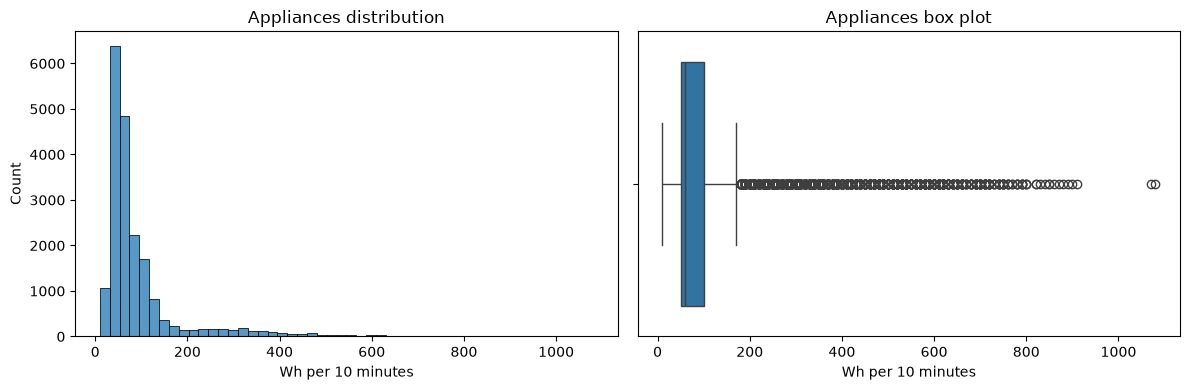

In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(df.Appliances,bins=50,ax=ax[0]); ax[0].set(title='Appliances distribution',xlabel='Wh per 10 minutes')
sns.boxplot(x=df.Appliances,ax=ax[1]); ax[1].set(title='Appliances box plot',xlabel='Wh per 10 minutes')
plt.tight_layout()

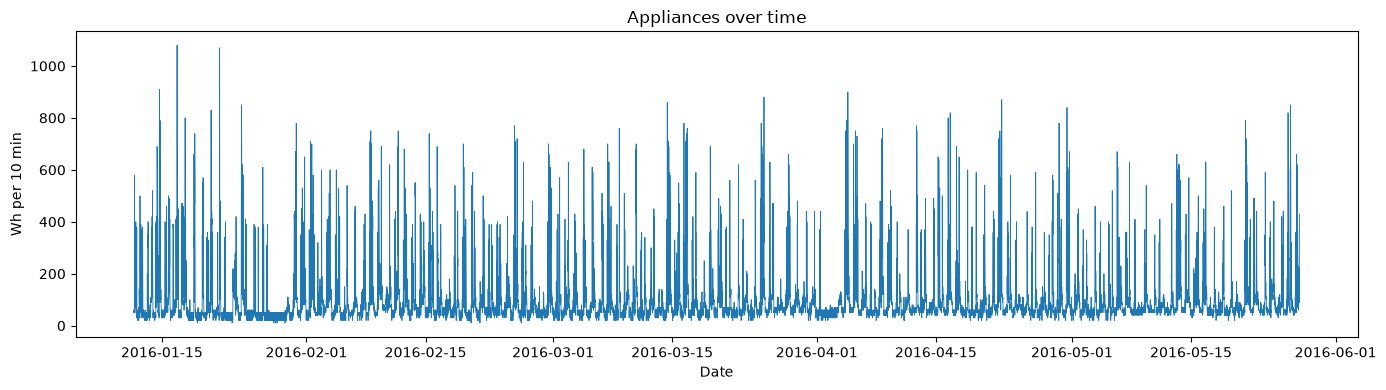

In [5]:
df['date']=__import__('pandas').to_datetime(df.date)
fig,ax=plt.subplots(figsize=(14,4)); ax.plot(df.date,df.Appliances,lw=.6); ax.set(title='Appliances over time',xlabel='Date',ylabel='Wh per 10 min'); plt.tight_layout()

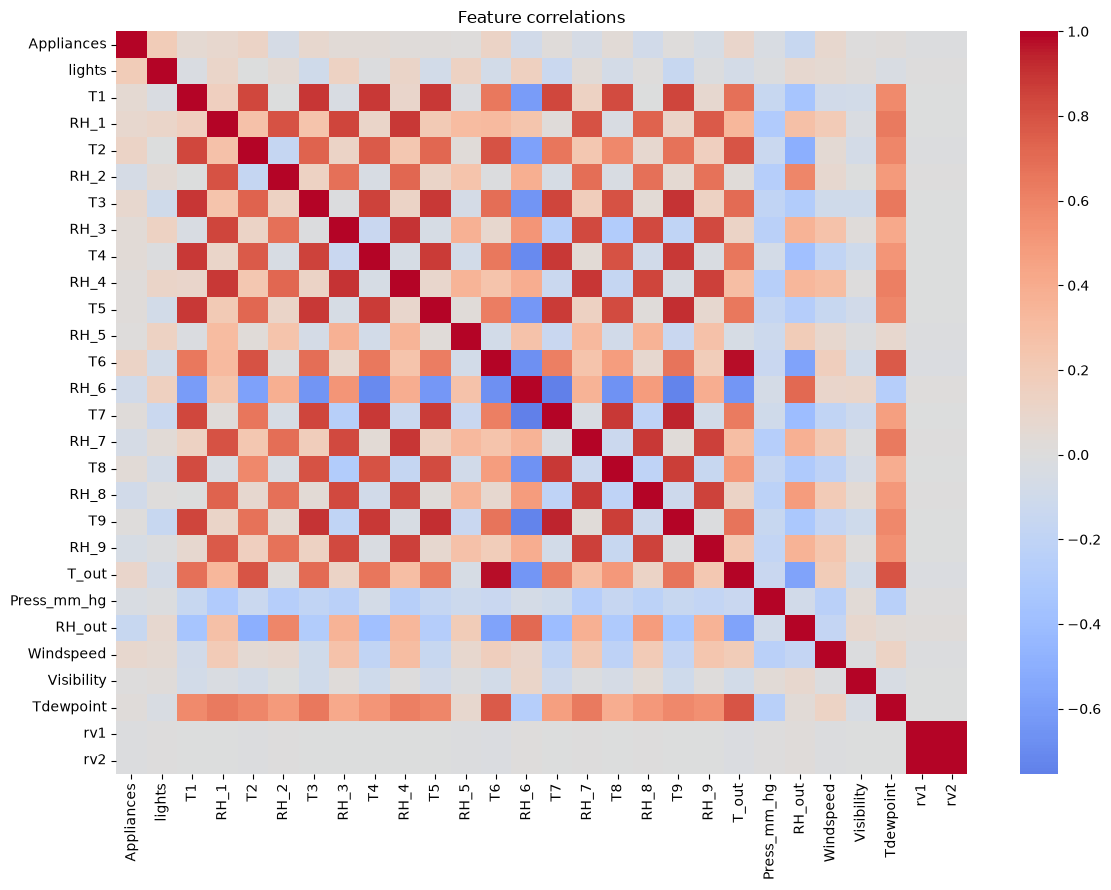

In [6]:
plt.figure(figsize=(12,9)); sns.heatmap(df.select_dtypes('number').corr(),cmap='coolwarm',center=0); plt.title('Feature correlations'); plt.tight_layout()

## Findings
This acquisition contains 19,735 records and 29 columns with no missing cells. Inspect plots and summary statistics before interpreting large values; they can represent genuine activity. Check rv1/rv2 redundancy. Save presentation figures from these cells after reviewing them.

## Data quality and timestamp inspection

This section checks the sampling timeline, repeated timestamps, target range, and missingness percentages. Gaps are reported rather than silently filled.

In [7]:
import pandas as pd
df['date']=pd.to_datetime(df.date)
quality=pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'missing_pct':100*df.isna().mean(),'n_unique':df.nunique()})
quality


,dtype,missing,missing_pct,n_unique
date,datetime64[us],0,0.0,19735
Appliances,int64,0,0.0,92
lights,int64,0,0.0,8
T1,float64,0,0.0,722
RH_1,float64,0,0.0,2547
T2,float64,0,0.0,1650
RH_2,float64,0,0.0,3376
T3,float64,0,0.0,1426
RH_3,float64,0,0.0,2618
T4,float64,0,0.0,1390


### Sampling intervals

The target is the next *observed* row. Checking intervals makes any departures from ten minutes visible before interpreting the forecasting horizon.

In [8]:
intervals=df.date.sort_values().diff().dropna().dt.total_seconds().div(60)
intervals.describe(), intervals.value_counts().head(10), (intervals!=10).sum()


(count    19734.0
 mean        10.0
 std          0.0
 min         10.0
 25%         10.0
 50%         10.0
 75%         10.0
 max         10.0
 Name: date, dtype: float64,
 date
 10.0    19734
 Name: count, dtype: int64,
 np.int64(0))

### Target distribution and high-use observations

The quantiles describe the skew and tail. High observations are retained because they may reflect real appliance use; this plot alone does not label them as errors or waste.

In [9]:
df.Appliances.quantile([0,.25,.5,.75,.9,.95,.99,1]), df.nlargest(10,'Appliances')[['date','Appliances','lights']]


(0.00      10.0
 0.25      50.0
 0.50      60.0
 0.75     100.0
 0.90     196.0
 0.95     330.0
 0.99     576.6
 1.00    1080.0
 Name: Appliances, dtype: float64,
                      date  Appliances  lights
 731   2016-01-16 18:50:00        1080      30
 1451  2016-01-21 18:50:00        1070      30
 432   2016-01-14 17:00:00         910       0
 12088 2016-04-04 15:40:00         900       0
 1452  2016-01-21 19:00:00         890      20
 10668 2016-03-25 19:00:00         880      10
 14693 2016-04-22 17:50:00         870       0
 9031  2016-03-14 10:10:00         860       0
 1821  2016-01-24 08:30:00         850      20
 19582 2016-05-26 16:40:00         850       0)

### Daily and weekly patterns

Hourly and weekday averages summarize recurring patterns. These group averages are descriptive and may be affected by the short, single-home collection period.

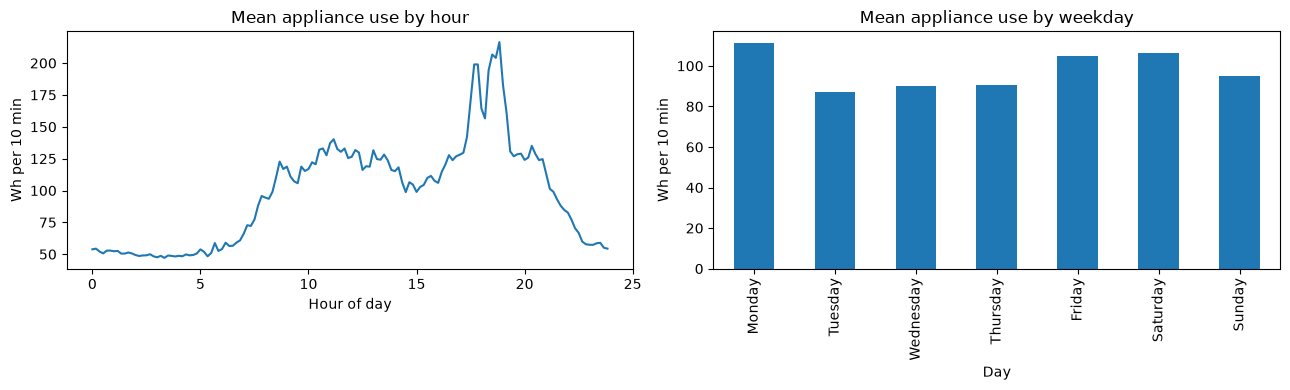

In [10]:
df['hour']=df.date.dt.hour + df.date.dt.minute/60
df['weekday']=df.date.dt.day_name()
fig,ax=plt.subplots(1,2,figsize=(13,4))
df.groupby('hour').Appliances.mean().plot(ax=ax[0]); ax[0].set(title='Mean appliance use by hour',xlabel='Hour of day',ylabel='Wh per 10 min')
df.groupby('weekday').Appliances.mean().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']).plot(kind='bar',ax=ax[1]); ax[1].set(title='Mean appliance use by weekday',xlabel='Day',ylabel='Wh per 10 min'); plt.tight_layout()


### Temperature and humidity associations

Scatter plots show association with representative indoor and outdoor sensors. Density and overlapping observations can obscure structure; these are not causal effects.

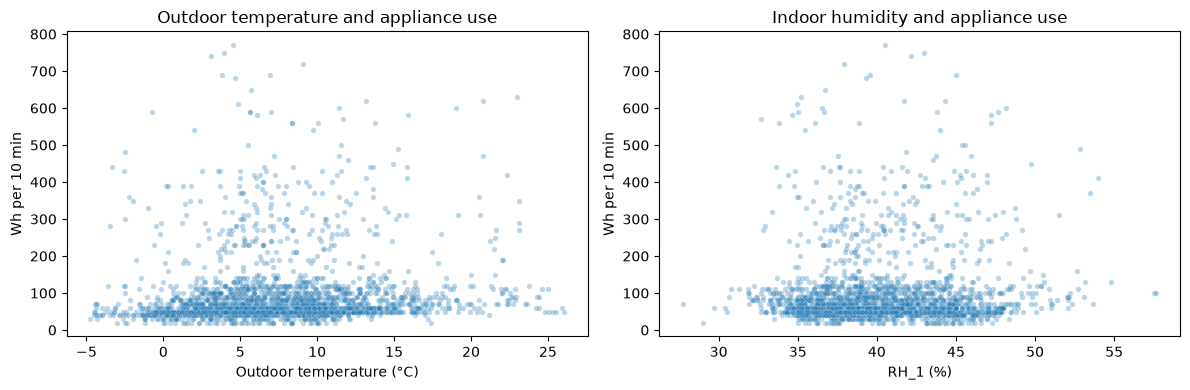

In [11]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.scatterplot(data=df.sample(min(2500,len(df)),random_state=42),x='T_out',y='Appliances',alpha=.3,s=15,ax=ax[0]); ax[0].set(title='Outdoor temperature and appliance use',xlabel='Outdoor temperature (°C)',ylabel='Wh per 10 min')
sns.scatterplot(data=df.sample(min(2500,len(df)),random_state=42),x='RH_1',y='Appliances',alpha=.3,s=15,ax=ax[1]); ax[1].set(title='Indoor humidity and appliance use',xlabel='RH_1 (%)',ylabel='Wh per 10 min'); plt.tight_layout()


### Lighting and random variables

The source includes lighting energy and two random variables. Compare the latter directly and examine whether they carry distinct information before treating them as meaningful predictors.

,rv1,rv2
rv1,1.0,1.0
rv2,1.0,1.0


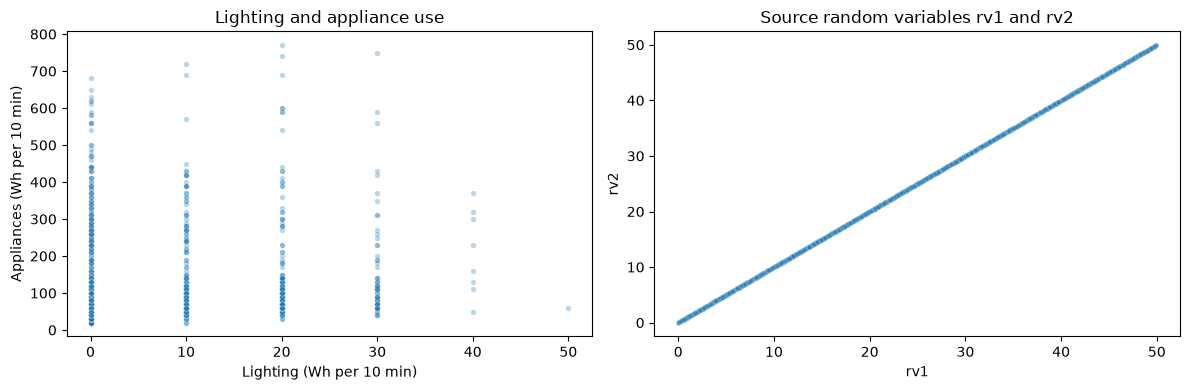

In [12]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.scatterplot(data=df.sample(min(2500,len(df)),random_state=42),x='lights',y='Appliances',alpha=.3,s=15,ax=ax[0]); ax[0].set(title='Lighting and appliance use',xlabel='Lighting (Wh per 10 min)',ylabel='Appliances (Wh per 10 min)')
sns.scatterplot(data=df.sample(min(2500,len(df)),random_state=42),x='rv1',y='rv2',alpha=.3,s=12,ax=ax[1]); ax[1].set(title='Source random variables rv1 and rv2',xlabel='rv1',ylabel='rv2'); plt.tight_layout()
df[['rv1','rv2']].corr()


### Correlation and collinearity review

The largest absolute correlations can signal redundant predictors. They are useful for understanding model inputs, but they do not prove that a sensor causes a change in appliance use.

In [13]:
corr=df.select_dtypes('number').corr()
target_corr=corr.Appliances.drop('Appliances').sort_values(key=abs,ascending=False)
target_corr.head(15)


hour         0.217152
lights       0.197278
RH_out      -0.152282
T2           0.120073
T6           0.117638
T_out        0.099155
RH_8        -0.094039
Windspeed    0.087122
RH_1         0.086031
T3           0.085060
RH_6        -0.083178
RH_2        -0.060465
RH_7        -0.055642
T1           0.055447
RH_9        -0.051462
Name: Appliances, dtype: float64

## EDA conclusions

Summarize the actual observations above: target skew and range, any timestamp gaps, time-of-day pattern, and the strongest descriptive associations. State explicitly that this is a single-home observational dataset and that correlation does not establish cause.

In [14]:
print(f'Rows: {len(df):,}; columns: {df.shape[1]}; missing cells: {int(df.isna().sum().sum())}; duplicate timestamps: {int(df.date.duplicated().sum())}')
print('Median interval (minutes):', intervals.median(), '| non-10-minute intervals:', int((intervals!=10).sum()))
print('Largest absolute target correlations:')
display(target_corr.head(8).to_frame('correlation'))


Rows: 19,735; columns: 31; missing cells: 0; duplicate timestamps: 0
Median interval (minutes): 10.0 | non-10-minute intervals: 0
Largest absolute target correlations:


,correlation
hour,0.217152
lights,0.197278
RH_out,-0.152282
T2,0.120073
T6,0.117638
T_out,0.099155
RH_8,-0.094039
Windspeed,0.087122
